## 🔧 **SETUP**

In [50]:
import os

#  Imposta il percorso della cartella condivisa (aggiorna il nome se diverso)
shared_folder = "/kaggle/input/microwave-ai/Microwave AI"

# Controlla se la cartella esiste e spostati al suo interno
if os.path.exists(shared_folder):
    os.chdir(shared_folder)
    print(f"✅ Cartella impostata correttamente:\n{os.getcwd()}")
else:
    print("❌ La cartella 'Microwave AI non trovata.")


✅ Cartella impostata correttamente:
/kaggle/input/microwave-ai/Microwave AI


## ⚙️ **Libraries Import**

In [51]:
# Set seed for reproducibility
SEED = 104

# Import necessary libraries
import csv

# Set environment variables before importing modules
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['MPLCONFIGDIR'] = os.getcwd() + '/configs/'

csv_file = "./all_models_log.csv"

# Suppress warnings
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=Warning)

# Import necessary modules
import logging
import random
import numpy as np

# Set seeds for random number generators in NumPy and Python
np.random.seed(SEED)
random.seed(SEED)

# Import PyTorch
import torch
torch.manual_seed(SEED)
from torch import nn
# from torchsummary import summary
from torch.utils.data import TensorDataset, DataLoader

if torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    device = torch.device("cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")

# Import other libraries
import copy
from datetime import datetime
import shutil
from itertools import product
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plot display settings
sns.set(font_scale=1.4)
sns.set_style('white')
plt.rc('font', size=14)
%matplotlib inline


PyTorch version: 2.6.0+cu124
Device: cuda


## ⏳ **Data Loading**

In [52]:
# =========================================
# 📊 DATA LOADING
# =========================================

# Load the datasets
try:
    train_df = pd.read_csv('./pirate_pain_train.csv')
    labels_df = pd.read_csv('./pirate_pain_train_labels.csv')
    test_df = pd.read_csv('./pirate_pain_test.csv')

    print("✅ Datasets loaded successfully!")

except FileNotFoundError as e:
    print(f"❌ Error loading datasets: {e}")
    print("Please ensure the CSV files are in the correct directory.")
    print("Current working directory:", os.getcwd())
except Exception as e:
    print(f"❌ An unexpected error occurred during data loading: {e}")



✅ Datasets loaded successfully!


In [53]:
#set directory to working and create model ddirectoy
shared_folder = "/kaggle/working"
os.chdir(shared_folder)
os.makedirs("models", exist_ok=True)

## 🔎 **Exploration and Data Analysis**

In [54]:
# Remove rows with any missing values
train_df.dropna(axis=0, how='any', inplace=True)
labels_df.dropna(axis=0, how='any', inplace=True)
test_df.dropna(axis=0, how='any', inplace=True)

# Print the shape of the DataFrame
print(f"Train DF shape: {train_df.shape}")
print(f"Labels DF shape: {labels_df.shape}")
print(f"Test DF shape: {test_df.shape}")

Train DF shape: (105760, 40)
Labels DF shape: (661, 2)
Test DF shape: (211840, 40)


In [55]:
#Train_df Overview
train_df.info()
print(train_df.describe())
train_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   105760 non-null  int64  
 1   time           105760 non-null  int64  
 2   pain_survey_1  105760 non-null  int64  
 3   pain_survey_2  105760 non-null  int64  
 4   pain_survey_3  105760 non-null  int64  
 5   pain_survey_4  105760 non-null  int64  
 6   n_legs         105760 non-null  object 
 7   n_hands        105760 non-null  object 
 8   n_eyes         105760 non-null  object 
 9   joint_00       105760 non-null  float64
 10  joint_01       105760 non-null  float64
 11  joint_02       105760 non-null  float64
 12  joint_03       105760 non-null  float64
 13  joint_04       105760 non-null  float64
 14  joint_05       105760 non-null  float64
 15  joint_06       105760 non-null  float64
 16  joint_07       105760 non-null  float64
 17  joint_08       105760 non-nul

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,0,2,1,two,two,two,1.094705,...,3.499558e-06,1.945042e-06,0.000004,1.153299e-05,0.000004,0.017592,0.013508,0.026798,0.027815,0.5
1,0,1,2,2,2,2,two,two,two,1.135183,...,3.976952e-07,6.765107e-07,0.000006,4.643774e-08,0.000000,0.013352,0.000000,0.013377,0.013716,0.5
2,0,2,2,0,2,2,two,two,two,1.080745,...,1.533820e-07,1.698525e-07,0.000001,2.424536e-06,0.000003,0.016225,0.008110,0.024097,0.023105,0.5
3,0,3,2,2,2,2,two,two,two,0.938017,...,1.006865e-05,5.511079e-07,0.000002,5.432416e-08,0.000000,0.011832,0.007450,0.028613,0.024648,0.5
4,0,4,2,2,2,2,two,two,two,1.090185,...,4.437266e-06,1.735459e-07,0.000002,5.825366e-08,0.000007,0.005360,0.002532,0.033026,0.025328,0.5


In [56]:
# ===================================================
# DATA TYPE CONVERSION - train_df
# ===================================================

# 1️ Convert all 'joint_' columns (from index 9 onward) to float32
train_df[train_df.columns[9:]] = train_df[train_df.columns[9:]].astype(np.float32)

# 2️ Convert 'n_legs', 'n_hands', 'n_eyes' from string to int64
cols_to_convert_to_int = ['n_legs', 'n_hands', 'n_eyes']

# Mapping of number words to integers
string_to_int_map = {
    'one+peg_leg': 1,
    'one+hook_hand': 1,
    'one+eye_patch': 1,
    'zero': 0,
    'one': 1,
    'two': 2
}

# Apply conversion
for col in cols_to_convert_to_int:
    train_df[col] = (
        train_df[col]
        .replace(string_to_int_map)             # replace number words
        .apply(pd.to_numeric, errors='coerce')  # convert to numeric
        .fillna(0)                              # replace NaN with 0
        .astype('int64')                        # ensure final dtype
    )

# 3 Display confirmation of type changes
print("\n✅ Data type conversion completed - Train DF\n")
train_df.info()
train_df.head()


✅ Data type conversion completed - Train DF

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105760 entries, 0 to 105759
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   105760 non-null  int64  
 1   time           105760 non-null  int64  
 2   pain_survey_1  105760 non-null  int64  
 3   pain_survey_2  105760 non-null  int64  
 4   pain_survey_3  105760 non-null  int64  
 5   pain_survey_4  105760 non-null  int64  
 6   n_legs         105760 non-null  int64  
 7   n_hands        105760 non-null  int64  
 8   n_eyes         105760 non-null  int64  
 9   joint_00       105760 non-null  float32
 10  joint_01       105760 non-null  float32
 11  joint_02       105760 non-null  float32
 12  joint_03       105760 non-null  float32
 13  joint_04       105760 non-null  float32
 14  joint_05       105760 non-null  float32
 15  joint_06       105760 non-null  float32
 16  joint_07       105760 non-nu

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,0,2,1,2,2,2,1.094705,...,3.499558e-06,1.945042e-06,0.000004,1.153299e-05,0.000004,0.017592,0.013508,0.026798,0.027815,0.5
1,0,1,2,2,2,2,2,2,2,1.135183,...,3.976952e-07,6.765108e-07,0.000006,4.643774e-08,0.000000,0.013352,0.000000,0.013377,0.013716,0.5
2,0,2,2,0,2,2,2,2,2,1.080745,...,1.533820e-07,1.698525e-07,0.000001,2.424536e-06,0.000003,0.016225,0.008110,0.024097,0.023105,0.5
3,0,3,2,2,2,2,2,2,2,0.938017,...,1.006865e-05,5.511079e-07,0.000002,5.432416e-08,0.000000,0.011832,0.007450,0.028613,0.024648,0.5
4,0,4,2,2,2,2,2,2,2,1.090185,...,4.437265e-06,1.735459e-07,0.000002,5.825366e-08,0.000007,0.005360,0.002532,0.033026,0.025328,0.5


In [57]:
# ===============================================
# DATA TYPE CONVERSION - test_df
# ===============================================

# 1️ Convert all 'joint_' columns (from index 9 onward) to float32
test_df[test_df.columns[9:]] = test_df[test_df.columns[9:]].astype(np.float32)

# 2️ Convert 'n_legs', 'n_hands', 'n_eyes' from string to int64
cols_to_convert_to_int = ['n_legs', 'n_hands', 'n_eyes']

# Mapping of number words to integers
string_to_int_map = {
    'one+peg_leg': 1,
    'one+hook_hand': 1,
    'one+eye_patch': 1,
    'zero': 0,
    'one': 1,
    'two': 2
}

# Apply conversion
for col in cols_to_convert_to_int:
    test_df[col] = (
        test_df[col]
        .replace(string_to_int_map)             # replace number words
        .apply(pd.to_numeric, errors='coerce')  # convert to numeric
        .fillna(0)                              # replace NaN with 0
        .astype('int64')                        # ensure final dtype
    )

# 3 Display confirmation of type changes
print("\n✅ Data type conversion completed - Test DF:\n")
test_df.info()
test_df.head()


✅ Data type conversion completed - Test DF:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211840 entries, 0 to 211839
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   211840 non-null  int64  
 1   time           211840 non-null  int64  
 2   pain_survey_1  211840 non-null  int64  
 3   pain_survey_2  211840 non-null  int64  
 4   pain_survey_3  211840 non-null  int64  
 5   pain_survey_4  211840 non-null  int64  
 6   n_legs         211840 non-null  int64  
 7   n_hands        211840 non-null  int64  
 8   n_eyes         211840 non-null  int64  
 9   joint_00       211840 non-null  float32
 10  joint_01       211840 non-null  float32
 11  joint_02       211840 non-null  float32
 12  joint_03       211840 non-null  float32
 13  joint_04       211840 non-null  float32
 14  joint_05       211840 non-null  float32
 15  joint_06       211840 non-null  float32
 16  joint_07       211840 non-nu

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,2,2,2,2,2,2,0.842535,...,0.000003,0.000004,0.000003,0.000003,0.000068,0.019372,0.066324,0.022228,0.013576,0.5
1,0,1,2,2,2,2,2,2,2,0.898836,...,0.000003,0.000004,0.000004,0.000003,0.000029,0.069747,0.080417,0.023650,0.038793,0.5
2,0,2,2,2,2,2,2,2,2,0.957765,...,0.000006,0.000004,0.000009,0.000004,0.000008,0.054968,0.058811,0.027023,0.054202,0.5
3,0,3,1,2,2,2,2,2,2,0.832596,...,0.000005,0.000004,0.000003,0.000004,0.000015,0.048695,0.047128,0.016151,0.024983,0.5
4,0,4,2,2,2,0,2,2,2,0.805972,...,0.000006,0.000004,0.000003,0.000003,0.000008,0.019762,0.031116,0.015618,0.017931,0.5


In [58]:
# ADD NUMERIC LABEL COLUMN

# Define the mapping from string labels to numerical values
label_to_numeric = {
    'no_pain': 0,
    'low_pain': 1,
    'high_pain': 2
}

# Create a new column 'label_numeric' using the mapping
labels_df['target'] = labels_df['label'].map(label_to_numeric)

labels_df.info()
labels_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 661 entries, 0 to 660
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   sample_index  661 non-null    int64 
 1   label         661 non-null    object
 2   target        661 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 15.6+ KB


,sample_index,label,target
0,0,no_pain,0
1,1,no_pain,0
2,2,low_pain,1
3,3,no_pain,0
4,4,no_pain,0


In [59]:
#Labels_df Overview

# Calculate the unique target labels and their counts
unique, count = np.unique(labels_df['label'], return_counts=True)
print('Target labels:', unique)
for i in range(len(unique)):
    print(f'Class {unique[i]} has {count[i]} samples')

print("\nLabels info:")
labels_df.info()
print("\nLabels head:")
labels_df.head()

Target labels: ['high_pain' 'low_pain' 'no_pain']
Class high_pain has 56 samples
Class low_pain has 94 samples
Class no_pain has 511 samples

Labels info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 661 entries, 0 to 660
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   sample_index  661 non-null    int64 
 1   label         661 non-null    object
 2   target        661 non-null    int64 
dtypes: int64(2), object(1)
memory usage: 15.6+ KB

Labels head:


,sample_index,label,target
0,0,no_pain,0
1,1,no_pain,0
2,2,low_pain,1
3,3,no_pain,0
4,4,no_pain,0


In [60]:
#Test_df Overview
test_df.info()
test_df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211840 entries, 0 to 211839
Data columns (total 40 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   sample_index   211840 non-null  int64  
 1   time           211840 non-null  int64  
 2   pain_survey_1  211840 non-null  int64  
 3   pain_survey_2  211840 non-null  int64  
 4   pain_survey_3  211840 non-null  int64  
 5   pain_survey_4  211840 non-null  int64  
 6   n_legs         211840 non-null  int64  
 7   n_hands        211840 non-null  int64  
 8   n_eyes         211840 non-null  int64  
 9   joint_00       211840 non-null  float32
 10  joint_01       211840 non-null  float32
 11  joint_02       211840 non-null  float32
 12  joint_03       211840 non-null  float32
 13  joint_04       211840 non-null  float32
 14  joint_05       211840 non-null  float32
 15  joint_06       211840 non-null  float32
 16  joint_07       211840 non-null  float32
 17  joint_08       211840 non-nul

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
0,0,0,2,2,2,2,2,2,2,0.842535,...,0.000003,0.000004,0.000003,0.000003,0.000068,0.019372,0.066324,0.022228,0.013576,0.5
1,0,1,2,2,2,2,2,2,2,0.898836,...,0.000003,0.000004,0.000004,0.000003,0.000029,0.069747,0.080417,0.023650,0.038793,0.5
2,0,2,2,2,2,2,2,2,2,0.957765,...,0.000006,0.000004,0.000009,0.000004,0.000008,0.054968,0.058811,0.027023,0.054202,0.5
3,0,3,1,2,2,2,2,2,2,0.832596,...,0.000005,0.000004,0.000003,0.000004,0.000015,0.048695,0.047128,0.016151,0.024983,0.5
4,0,4,2,2,2,0,2,2,2,0.805972,...,0.000006,0.000004,0.000003,0.000003,0.000008,0.019762,0.031116,0.015618,0.017931,0.5


## 📊 **Data Visualization**

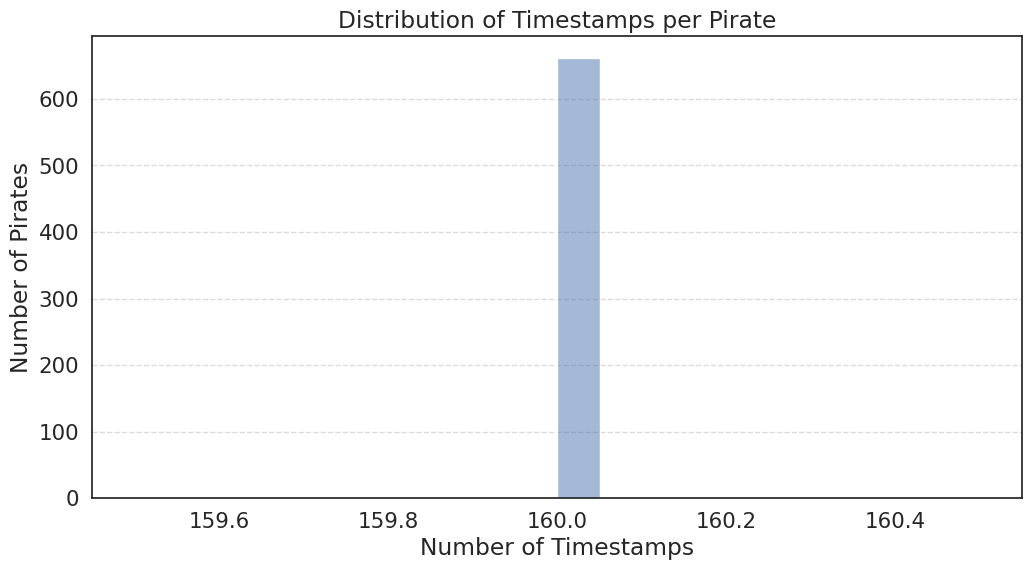

Descriptive statistics for timestamps per pirate:
count    661.0
mean     160.0
std        0.0
min      160.0
25%      160.0
50%      160.0
75%      160.0
max      160.0
Name: time, dtype: float64


In [61]:
# Calculate the number of timestamps for each unique pirate (sample_index)
timestamps_per_pirate = train_df.groupby('sample_index')['time'].count()

# Create a histogram of these counts
plt.figure(figsize=(12, 6))
sns.histplot(timestamps_per_pirate, bins=20, kde=True)
plt.title('Distribution of Timestamps per Pirate')
plt.xlabel('Number of Timestamps')
plt.ylabel('Number of Pirates')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Display some descriptive statistics for context
print("Descriptive statistics for timestamps per pirate:")
print(timestamps_per_pirate.describe())

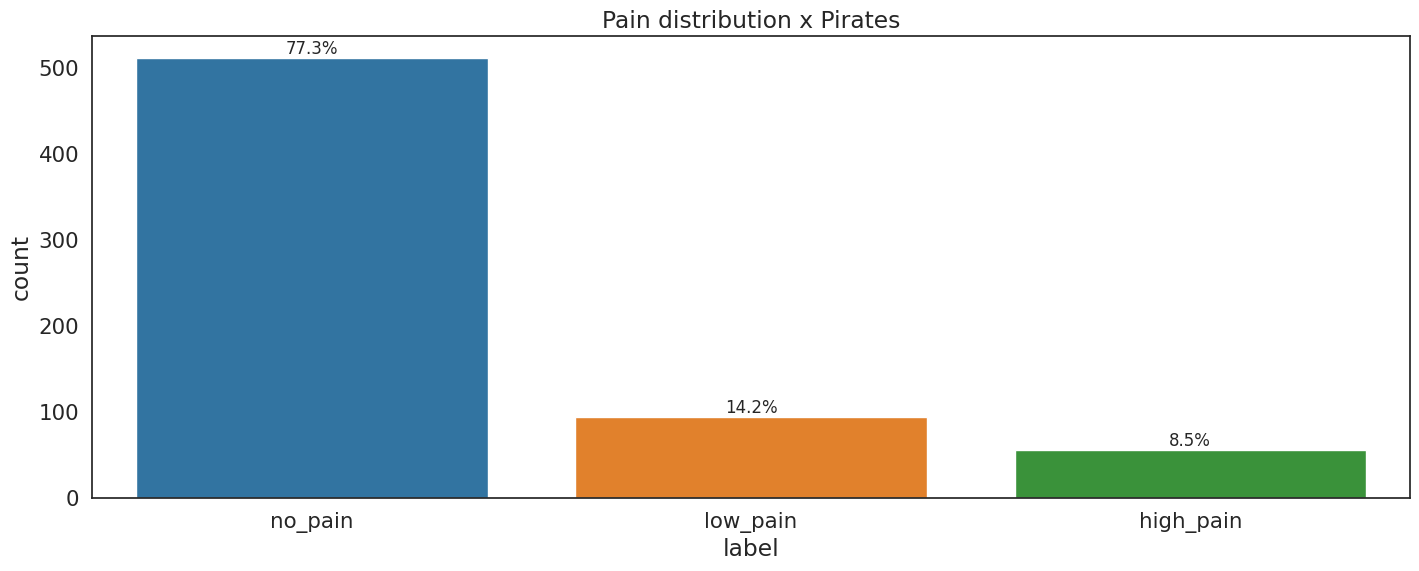

In [62]:
# Visualise the count of timestamps for each activity
plt.figure(figsize=(17, 6))
ax = sns.countplot(
    x='label',
    data=labels_df,
    order=labels_df['label'].value_counts().index,
    palette='tab10'
)

# Calculate percentages and add them on top of the bars
total = len(labels_df)
for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height()/total)
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontsize=12)

# Set the title of the plot
plt.title('Pain distribution x Pirates')

# Display the plot
plt.show()

In [63]:
def plot_pirate_joint_movements(df, pirate_id, joint_columns):
    """
    Visualise the movement of specified joint columns for a given pirate over time.

    Args:
        df (pd.DataFrame): The input DataFrame containing joint data and 'time' column.
        pirate_id (int): The sample_index of the pirate to plot.
        joint_columns (list): A list of strings, each representing a joint column to plot.
    """
    # Filter the DataFrame for the specified pirate_id
    pirate_data = df[df['sample_index'] == pirate_id]

    # Select 'time' and the specified joint columns
    data_to_plot = pirate_data[['time'] + joint_columns]

    # Set 'time' as index for plotting
    data_to_plot = data_to_plot.set_index('time')

    # Plot the joint data for each axis as subplots
    # Ensure enough height for multiple subplots
    fig, axes = plt.subplots(len(joint_columns), 1, figsize=(17, 3 * len(joint_columns)), sharex=True)

    # Handle case where there's only one joint_column (axes is not an array)
    if len(joint_columns) == 1:
        axes = [axes]

    for i, col in enumerate(joint_columns):
        axes[i].plot(data_to_plot.index, data_to_plot[col], label=col)
        axes[i].set_title(f'{col} Movement')
        axes[i].legend(loc='lower right')
        axes[i].grid(True, linestyle='--', alpha=0.7)
        if i == len(joint_columns) - 1:
            axes[i].set_xlabel('Time')
        axes[i].set_ylabel('Value')

    fig.suptitle(f'Joint Movements for Pirate ID: {pirate_id}', y=0.99, fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Adjust layout to prevent title overlap
    plt.show()

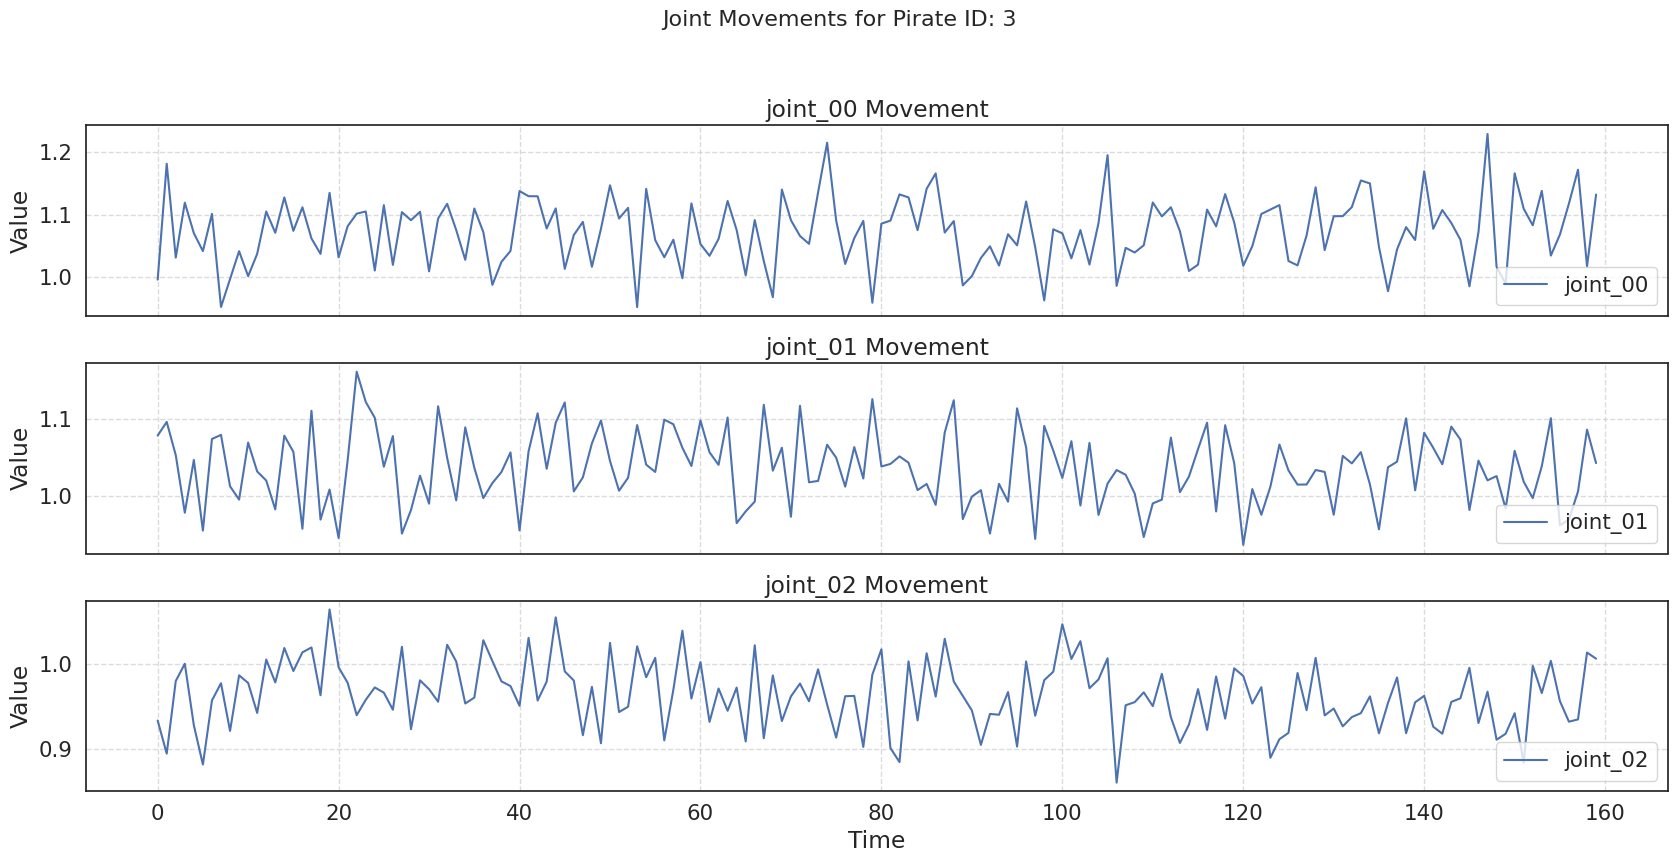

In [64]:
selected_pirate_id = 3
selected_joint_columns = ['joint_00', 'joint_01', 'joint_02']

plot_pirate_joint_movements(train_df, selected_pirate_id, selected_joint_columns)

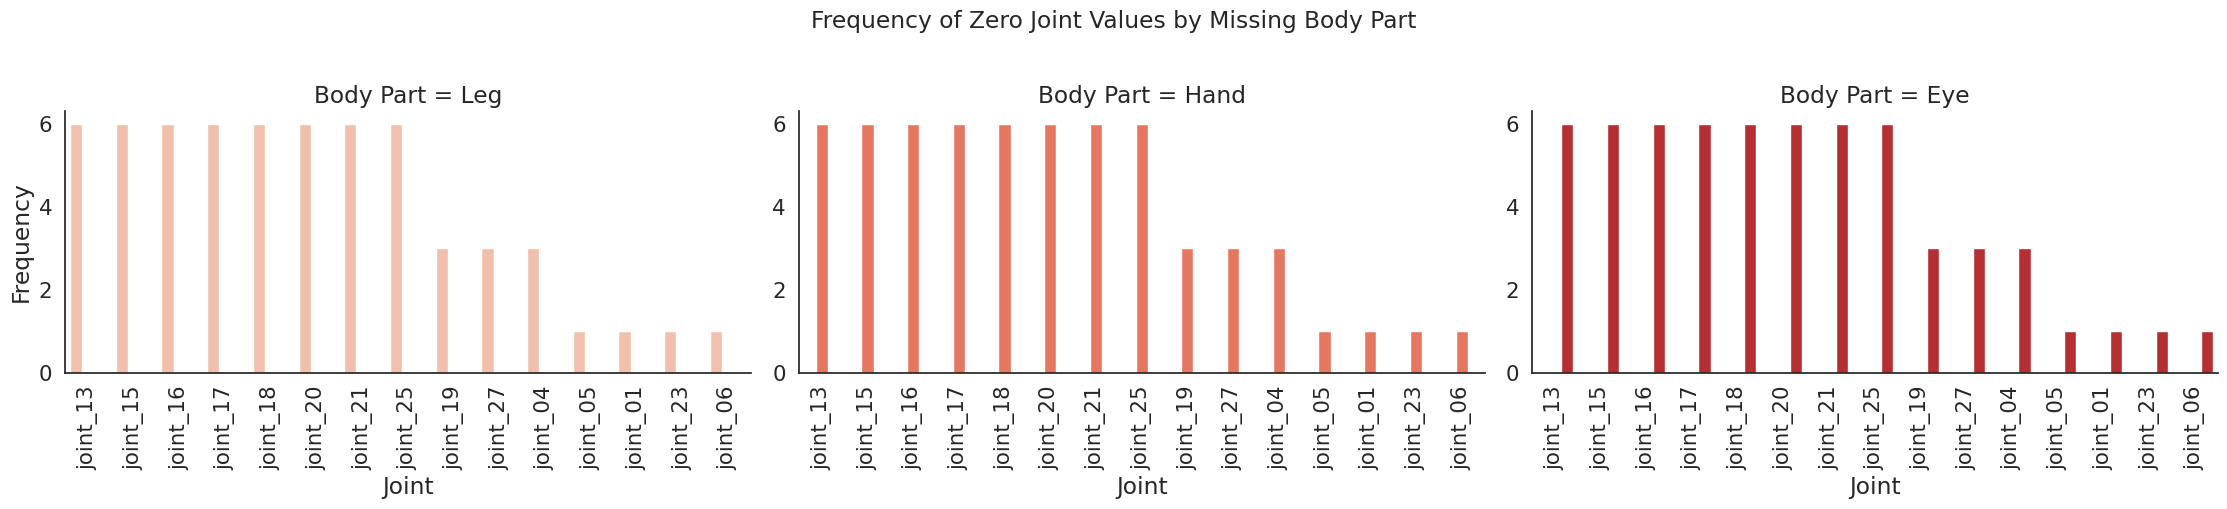

In [65]:
# ====================================================================
# VISUALIZE CORRELATIONS BETWEEN MISSING BODY PARTS AND ZERO JOINT VALUES
# ====================================================================

# Aggregate the zero joint information
agg_data = {'Leg': [], 'Hand': [], 'Eye': []}

pirates_with_one_missing = train_df[(train_df['n_legs'] == 1) |
                                      (train_df['n_hands'] == 1) |
                                      (train_df['n_eyes'] == 1)]

for sample_index, pirate_data in pirates_with_one_missing.groupby('sample_index'):
    joint_cols = [col for col in pirate_data.columns if 'joint_' in col]
    zero_joints = pirate_data[joint_cols].columns[(pirate_data[joint_cols] == 0).any()].tolist()

    # Determine which body part(s) are missing for this pirate
    missing_parts = []
    if pirate_data['n_legs'].iloc[0] == 1:
        missing_parts.append('Leg')
    if pirate_data['n_hands'].iloc[0] == 1:
        missing_parts.append('Hand')
    if pirate_data['n_eyes'].iloc[0] == 1:
        missing_parts.append('Eye')

    # Append the zero joints to the corresponding missing body part lists
    for part in missing_parts:
        agg_data[part].extend(zero_joints)

# Count the occurrences of each zero joint for each missing body part
agg_counts = {part: pd.Series(joints).value_counts() for part, joints in agg_data.items()}

# Prepare data for a single plot with faceting
plot_data = []
for part, counts in agg_counts.items():
    for joint, freq in counts.items():
        plot_data.append({'Body Part': part, 'Joint': joint, 'Frequency': freq})

plot_df = pd.DataFrame(plot_data)

# Create a single plot with faceting and a color palette starting from red
g = sns.catplot(
    data=plot_df,
    x='Joint',
    y='Frequency',
    col='Body Part',
    hue='Body Part', # Use hue to differentiate colors by Body Part
    kind='bar',
    sharey=False,
    height=5,
    aspect=1.5,
    palette='Reds' # Use a color palette starting from red
)

# Rotate x-axis labels for better readability
g.set_xticklabels(rotation=90)
g.fig.suptitle('Frequency of Zero Joint Values by Missing Body Part', y=1.02)
plt.tight_layout()
plt.show()

## **🛠️MODEL BUILDING**

In [66]:
#=================================================
#    FUNZIONE SUMMARY PER RNN
#=================================================


def recurrent_summary(model, input_size):
    """
    Custom summary function that emulates torchinfo's output while correctly
    counting parameters for RNN/GRU/LSTM layers.

    This function is designed for models whose direct children are
    nn.Linear, nn.RNN, nn.GRU, or nn.LSTM layers.

    Args:
        model (nn.Module): The model to analyze.
        input_size (tuple): Shape of the input tensor (e.g., (seq_len, features)).
    """

    # Dictionary to store output shapes captured by forward hooks
    output_shapes = {}
    # List to track hook handles for later removal
    hooks = []

    def get_hook(name):
        """Factory function to create a forward hook for a specific module."""
        def hook(module, input, output):
            # Handle RNN layer outputs (returns a tuple)
            if isinstance(output, tuple):
                # output[0]: all hidden states with shape (batch, seq_len, hidden*directions)
                shape1 = list(output[0].shape)
                shape1[0] = -1  # Replace batch dimension with -1

                # output[1]: final hidden state h_n (or tuple (h_n, c_n) for LSTM)
                if isinstance(output[1], tuple):  # LSTM case: (h_n, c_n)
                    shape2 = list(output[1][0].shape)  # Extract h_n only
                else:  # RNN/GRU case: h_n only
                    shape2 = list(output[1].shape)

                # Replace batch dimension (middle position) with -1
                shape2[1] = -1

                output_shapes[name] = f"[{shape1}, {shape2}]"

            # Handle standard layer outputs (e.g., Linear)
            else:
                shape = list(output.shape)
                shape[0] = -1  # Replace batch dimension with -1
                output_shapes[name] = f"{shape}"
        return hook

    # 1. Determine the device where model parameters reside
    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")  # Fallback for models without parameters

    # 2. Create a dummy input tensor with batch_size=1
    dummy_input = torch.randn(1, *input_size).to(device)

    # 3. Register forward hooks on target layers
    # Iterate through direct children of the model (e.g., self.rnn, self.classifier)
    for name, module in model.named_children():
        if isinstance(module, (nn.Linear, nn.RNN, nn.GRU, nn.LSTM)):
            # Register the hook and store its handle for cleanup
            hook_handle = module.register_forward_hook(get_hook(name))
            hooks.append(hook_handle)

    # 4. Execute a dummy forward pass in evaluation mode
    model.eval()
    with torch.no_grad():
        try:
            model(dummy_input)
        except Exception as e:
            print(f"Error during dummy forward pass: {e}")
            # Clean up hooks even if an error occurs
            for h in hooks:
                h.remove()
            return

    # 5. Remove all registered hooks
    for h in hooks:
        h.remove()

    # --- 6. Print the summary table ---

    print("-" * 79)
    # Column headers
    print(f"{'Layer (type)':<25} {'Output Shape':<28} {'Param #':<18}")
    print("=" * 79)

    total_params = 0
    total_trainable_params = 0

    # Iterate through modules again to collect and display parameter information
    for name, module in model.named_children():
        if name in output_shapes:
            # Count total and trainable parameters for this module
            module_params = sum(p.numel() for p in module.parameters())
            trainable_params = sum(p.numel() for p in module.parameters() if p.requires_grad)

            total_params += module_params
            total_trainable_params += trainable_params

            # Format strings for display
            layer_name = f"{name} ({type(module).__name__})"
            output_shape_str = str(output_shapes[name])
            params_str = f"{trainable_params:,}"

            print(f"{layer_name:<25} {output_shape_str:<28} {params_str:<15}")

    print("=" * 79)
    print(f"Total params: {total_params:,}")
    print(f"Trainable params: {total_trainable_params:,}")
    print(f"Non-trainable params: {total_params - total_trainable_params:,}")
    print("-" * 79)

In [67]:
#==========================================
#      MODELLO RNN
#==========================================

class RecurrentClassifier(nn.Module):
    """
    Generic RNN classifier (RNN, LSTM, GRU).
    Uses the last hidden state for classification.
    """
    def __init__(
            self,
            input_size,
            hidden_size,
            num_layers,
            num_classes,
            rnn_type='GRU',        # 'RNN', 'LSTM', or 'GRU'
            bidirectional=False,
            dropout_rate=0.2
            ):
        super().__init__()

        self.rnn_type = rnn_type
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        self.bidirectional = bidirectional

        # Map string name to PyTorch RNN class
        rnn_map = {
            'RNN': nn.RNN,
            'LSTM': nn.LSTM,
            'GRU': nn.GRU
        }

        if rnn_type not in rnn_map:
            raise ValueError("rnn_type must be 'RNN', 'LSTM', or 'GRU'")

        rnn_module = rnn_map[rnn_type]

        # Dropout is only applied between layers (if num_layers > 1)
        dropout_val = dropout_rate if num_layers > 1 else 0

        # Create the recurrent layer
        self.rnn = rnn_module(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,       # Input shape: (batch, seq_len, features)
            bidirectional=bidirectional,
            dropout=dropout_val
        )

        # Calculate input size for the final classifier
        if self.bidirectional:
            classifier_input_size = hidden_size * 2 # Concat fwd + bwd
        else:
            classifier_input_size = hidden_size

        # Final classification layer
        self.classifier = nn.Linear(classifier_input_size, num_classes)

    def forward(self, x):
        """
        x shape: (batch_size, seq_length, input_size)
        """

        # rnn_out shape: (batch_size, seq_len, hidden_size * num_directions)
        rnn_out, hidden = self.rnn(x)

        # LSTM returns (h_n, c_n), we only need h_n
        if self.rnn_type == 'LSTM':
            hidden = hidden[0]

        # hidden shape: (num_layers * num_directions, batch_size, hidden_size)

        if self.bidirectional:
            # Reshape to (num_layers, 2, batch_size, hidden_size)
            hidden = hidden.view(self.num_layers, 2, -1, self.hidden_size)

            # Concat last fwd (hidden[-1, 0, ...]) and bwd (hidden[-1, 1, ...])
            # Final shape: (batch_size, hidden_size * 2)
            hidden_to_classify = torch.cat([hidden[-1, 0, :, :], hidden[-1, 1, :, :]], dim=1)
        else:
            # Take the last layer's hidden state
            # Final shape: (batch_size, hidden_size)
            hidden_to_classify = hidden[-1]

        # Get logits
        logits = self.classifier(hidden_to_classify)
        return logits




## 🧠 **Model Training**

In [68]:
# Initialize best model tracking variables
best_model = None
best_performance = float('-inf')

In [69]:
def train_one_epoch(model, train_loader, criterion, optimizer, scaler, device, l1_lambda=0, l2_lambda=0):
    """
    Perform one complete training epoch through the entire training dataset.

    Args:
        model (nn.Module): The neural network model to train
        train_loader (DataLoader): PyTorch DataLoader containing training data batches
        criterion (nn.Module): Loss function (e.g., CrossEntropyLoss, MSELoss)
        optimizer (torch.optim): Optimization algorithm (e.g., Adam, SGD)
        scaler (GradScaler): PyTorch's gradient scaler for mixed precision training
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)
        l1_lambda (float): Lambda for L1 regularization
        l2_lambda (float): Lambda for L2 regularization

    Returns:
        tuple: (average_loss, f1 score) - Training loss and f1 score for this epoch
    """
    model.train()  # Set model to training mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Iterate through training batches
    for batch_idx, (inputs, targets) in enumerate(train_loader):
        # Move data to device (GPU/CPU)
        inputs, targets = inputs.to(device), targets.to(device)

        # Clear gradients from previous step
        optimizer.zero_grad(set_to_none=True)

        # Forward pass with mixed precision (if CUDA available)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            logits = model(inputs)
            loss = criterion(logits, targets)

            # Add L1 and L2 regularization
            l1_norm = sum(p.abs().sum() for p in model.parameters())
            l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            loss = loss + l1_lambda * l1_norm + l2_lambda * l2_norm


        # Backward pass with gradient scaling
        scaler.scale(loss).backward()

        # Gradient clipping to prevent exploding gradients
        scaler.unscale_(optimizer)  # Unscale gradients before clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        # Accumulate metrics
        running_loss += loss.item() * inputs.size(0)
        predictions = logits.argmax(dim=1)
        all_predictions.append(predictions.cpu().numpy())
        all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_f1 = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_f1

In [70]:
def validate_one_epoch(model, val_loader, criterion, device):
    """
    Perform one complete validation epoch through the entire validation dataset.

    Args:
        model (nn.Module): The neural network model to evaluate (must be in eval mode)
        val_loader (DataLoader): PyTorch DataLoader containing validation data batches
        criterion (nn.Module): Loss function used to calculate validation loss
        device (torch.device): Computing device ('cuda' for GPU, 'cpu' for CPU)

    Returns:
        tuple: (average_loss, accuracy) - Validation loss and accuracy for this epoch

    Note:
        This function automatically sets the model to evaluation mode and disables
        gradient computation for efficiency during validation.
    """
    model.eval()  # Set model to evaluation mode

    running_loss = 0.0
    all_predictions = []
    all_targets = []

    # Disable gradient computation for validation
    with torch.no_grad():
        for inputs, targets in val_loader:
            # Move data to device
            inputs, targets = inputs.to(device), targets.to(device)

            # Forward pass with mixed precision (if CUDA available)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                logits = model(inputs)
                loss = criterion(logits, targets)

            # Accumulate metrics
            running_loss += loss.item() * inputs.size(0)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu().numpy())
            all_targets.append(targets.cpu().numpy())

    # Calculate epoch metrics
    epoch_loss = running_loss / len(val_loader.dataset)
    epoch_accuracy = f1_score(
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        average='weighted'
    )

    return epoch_loss, epoch_accuracy

In [71]:
#==========================================
#     CSV - Models log
#==========================================
csv_file = "./all_models_log.csv"

# Initialize metrics tracking
training_history = {
    'train_loss': [],
    'val_loss': [],
    'train_f1': [],
    'val_f1': [],
    'val_accuracy_class_0': [],
    'val_accuracy_class_1': [],
    'val_accuracy_class_2': []
}

training_log = []

fieldnames = [
    "time","model_name","rnn_type", "epoch", "train_loss", "val_loss", "train_f1", "val_f1",
    "batch_size","window_size","stride","num_layers","layer_size","dropout_rate",
    "l1_lambda", "l2_lambda", "patience", "evaluation_metric",
    "accuracy_nopain", "accuracy_lowpain", "accuracy_highpain"
]


In [72]:
EXPERIMENT_NAME="GRU_bello"
RNN_TYPE="GRU"
BIDIRECTIONAL=True

In [73]:
#Fit function - Train the neural network model on the training data and validate on the validation data

def fit(model, train_loader, val_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):




    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")
    actual_epochs = epochs

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Evaluate model on validation data without updating weights
        val_loss, val_f1 = validate_one_epoch(
            model, val_loader, criterion, device
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['val_loss'].append(val_loss)
        training_history['train_f1'].append(train_f1)
        training_history['val_f1'].append(val_f1)

        # The accuracy per class will be calculated and logged after the training loop
        # Training configuration
        hyperparams = {
          "batch_size": BATCH_SIZE,
          "window_size": WINDOW_SIZE,
          "stride": STRIDE,
          "num_layers": HIDDEN_LAYERS,
          "layer_size": HIDDEN_SIZE,
          "dropout_rate": DROPOUT_RATE,
          "l1_lambda": L1_LAMBDA,
          "l2_lambda": L2_LAMBDA,
          "patience": PATIENCE,
          "evaluation_metric": evaluation_metric,
        }


        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                    f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} | "
                    f"Val: Loss={val_loss:.4f}, F1 Score={val_f1:.4f}")

        # Early stopping logic: monitor metric and save best model
        if patience > 0:
            current_metric = training_history[evaluation_metric][-1]
            is_improvement = (current_metric > best_metric) if mode == 'max' else (current_metric < best_metric)

            if is_improvement:
                best_metric = current_metric
                best_epoch = epoch
                torch.save(model.state_dict(), "./models/"+experiment_name+'_model.pt')
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= patience:
                    print(f"Early stopping triggered after {epoch} epochs.")
                    actual_epochs = best_epoch
                    break

    if patience > 0 and patience_counter < patience:
        actual_epochs = epoch
    # Restore best model weights if early stopping was used
    if restore_best_weights and patience > 0:
        model.load_state_dict(torch.load("./models/"+experiment_name+'_model.pt'))
        print(f"Best model restored from epoch {best_epoch} with {evaluation_metric} {best_metric:.4f}")

    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "./models/"+experiment_name+'_model.pt')

    row = {
          "time": datetime.now().strftime("%Y-%m-%d %H:%M"),
          "model_name": experiment_name,
          "rnn_type": f"{ 'bi' if BIDIRECTIONAL else '' }{RNN_TYPE}",
          "epoch": best_epoch,
          "train_loss": train_loss,
          "val_loss": val_loss,
          "train_f1": train_f1,
          "val_f1": best_metric,
          **hyperparams,
          "accuracy_nopain": 0,      # Placeholder, will be updated later
          "accuracy_lowpain": 0,     # Placeholder, will be updated later
          "accuracy_highpain": 0     # Placeholder, will be updated later
        }
    training_log.append(row)

    #print(row)
    #csv writing
    new_row = pd.DataFrame([row])
    if os.path.exists(csv_file):
      models_log = pd.read_csv(csv_file)
      models_log = models_log[models_log['model_name'] != row['model_name']]  # rimuovi duplicato
      models_log = pd.concat([models_log, new_row], ignore_index=True)
    else:
        models_log = new_row

    models_log.to_csv(csv_file, index=False)

    return model, training_history, actual_epochs


## **NETWORK HYPERPARAMTERS**

In [99]:
# Cross-validation
#EXPERIMENT_NAME="GRU_crossV_stider_test"
K = 5                    # Number of splits (5 and 10 are considered good values)
N_VAL_PIRATES = 131          # Number of users for validation split
#n_val_users is the number of unique pirates that will be assigned to the validation set every iteration
#every iteration creates a validation and training set of fixed quantity but the pirates inside are taken randomly
#this because I have to garantee that every set I create has unique sample_index pirates

# Training
EPOCHS = 300             # Maximum epochs (increase to improve performance)
PATIENCE = 60            # Early stopping patience (increase to improve performance)
VERBOSE = 1           # Print frequency

# Optimisation
LEARNING_RATE = 1e-3     # Learning rate
BATCH_SIZE = 16         # Batch size


WINDOW_SIZE = 80        # Input window size
STRIDE = 20             # Input stride

# Architecture
HIDDEN_LAYERS = 1        # Hidden layers
HIDDEN_SIZE = 128        # Neurons per layer
RNN_TYPE = 'GRU'         # Type of RNN architecture
BIDIRECTIONAL = True    # Bidirectional RNN

# Regularisation
DROPOUT_RATE = 0       # Dropout probability
L1_LAMBDA = 0            # L1 penalty
L2_LAMBDA = 0            # L2 penalty

# Training utilities
CRITERION = nn.CrossEntropyLoss() #the weights will be set up later!!

# Data dimensions
#num_features = 38
#num_classes = 3

## 🔄 **Data Processing**

In [75]:
# ====================================================================
# SPLIT DATASET IN TRAINING AND VALIDATION (Stratified Split)
# ====================================================================

# Merge train_df with labels_df to get labels for each sample_index
train_df_with_labels = pd.merge(train_df, labels_df, on='sample_index', how='left')

# Get unique pirates and their corresponding labels
unique_pirates_with_labels = train_df_with_labels[['sample_index', 'label']].drop_duplicates()

# Define the number of users for validation
N_VAL_PIRATES = 130


#train test split to stratify pirates equally in training and validation
train_pirates, val_pirates = train_test_split(
    unique_pirates_with_labels['sample_index'],
    test_size=N_VAL_PIRATES,
    stratify=unique_pirates_with_labels['label'],
    random_state=SEED
)

# Split the dataset into training, validation with previous results
train_df_split = train_df[train_df['sample_index'].isin(train_pirates)]
val_df_split = train_df[train_df['sample_index'].isin(val_pirates)]
test_df_split = test_df

# Print the shapes of the training, validation, and test sets
print(f'Training set shape: {train_df_split.shape}')
print(f'Validation set shape: {val_df_split.shape}')
print(f'Test set shape: {test_df_split.shape}')


#PAIN DISTRIBUTION IN SPLITS
print("\nLabel distribution in Training set:")
train_label_counts = train_df_split.merge(labels_df, on='sample_index')['label'].value_counts() / 160
train_total_pirates = train_label_counts.sum()
pain_map = {
    'no_pain':0,
    'low_pain':0,
    'high_pain':0
}
for label, count in train_label_counts.items():
    pain_map[label] = count
    percentage = (count / train_total_pirates) * 100
    print(f"{label}: {int(count)} pirates ({percentage:.2f}%)")

print("\nLabel distribution in Validation set:")
val_label_counts = val_df_split.merge(labels_df, on='sample_index')['label'].value_counts() / 160
val_total_pirates = val_label_counts.sum()
for label, count in val_label_counts.items():
    percentage = (count / val_total_pirates) * 100
    print(f"{label}: {int(count)} pirates ({percentage:.2f}%)")

Training set shape: (84960, 40)
Validation set shape: (20800, 40)
Test set shape: (211840, 40)

Label distribution in Training set:
no_pain: 410 pirates (77.21%)
low_pain: 76 pirates (14.31%)
high_pain: 45 pirates (8.47%)

Label distribution in Validation set:
no_pain: 101 pirates (77.69%)
low_pain: 18 pirates (13.85%)
high_pain: 11 pirates (8.46%)


In [76]:
#calculating class weights for unbalanced dataset
pain_class_weights = {
    'no_pain':0,
    'low_pain':0,
    'high_pain':0
}

NUMBER_OF_PAIN_CLASSES=len(pain_class_weights)

for pain_class in pain_map:
  #peso = (numero_totale_pirati_training / (numero_classi_di_dolore * numero_pirati_per_classe))
  pain_class_weights[pain_class] = (train_total_pirates/(NUMBER_OF_PAIN_CLASSES*pain_map[pain_class])).astype(np.float32)
print(pain_class_weights)

#creating list useful later for tensor transformation
pain_class_weights_list=list(pain_class_weights.values())

{'no_pain': 0.43170732, 'low_pain': 2.3289473, 'high_pain': 3.9333334}


In [77]:
# ====================================================================
# MIN MAX NORMALIZATION
# ====================================================================

columns_joint=train_df.columns[9:39]
train_min = train_df_split[columns_joint].min()
train_max = train_df_split[columns_joint].max()


train_df_split[columns_joint] = (train_df_split[columns_joint] - train_min) / (train_max - train_min)
val_df_split[columns_joint] = (val_df_split[columns_joint]- train_min) / (train_max - train_min)
test_df_split[columns_joint]  = (test_df_split[columns_joint]  - train_min) / (train_max - train_min)

train_df_split.head()
train_df_split.describe()

,sample_index,time,pain_survey_1,pain_survey_2,pain_survey_3,pain_survey_4,n_legs,n_hands,n_eyes,joint_00,...,joint_21,joint_22,joint_23,joint_24,joint_25,joint_26,joint_27,joint_28,joint_29,joint_30
count,84960.000000,84960.000000,84960.000000,84960.000000,84960.000000,84960.000000,84960.000000,84960.000000,84960.000000,84960.000000,...,8.496000e+04,8.496000e+04,84960.000000,84960.000000,8.496000e+04,84960.000000,84960.000000,84960.000000,84960.000000,84960.0
mean,324.497175,79.500000,1.632863,1.651930,1.650577,1.663136,1.990584,1.990584,1.990584,0.681905,...,3.134083e-05,3.682887e-05,0.000139,0.000933,1.124842e-04,0.034749,0.049315,0.035592,0.045655,0.5
std,192.755541,46.187391,0.682912,0.671972,0.668801,0.662073,0.096580,0.096580,0.096580,0.145482,...,3.847555e-03,4.677869e-03,0.005007,0.011949,3.741903e-03,0.050726,0.068489,0.043676,0.053503,0.0
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.5
25%,157.000000,39.750000,1.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,0.604279,...,4.538819e-08,1.400154e-07,0.000001,0.000008,7.667361e-07,0.007777,0.010179,0.011340,0.014079,0.5
50%,324.000000,79.500000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,0.726506,...,5.895492e-07,7.349369e-07,0.000004,0.000024,3.320377e-06,0.017760,0.026155,0.022627,0.028536,0.5
75%,490.000000,119.250000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,0.779942,...,1.973734e-06,2.277954e-06,0.000011,0.000069,1.056233e-05,0.040127,0.060028,0.042055,0.058568,0.5
max,660.000000,159.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,...,1.000000e+00,1.000000e+00,1.000000,1.000000,1.000000e+00,1.000000,1.000000,1.000000,1.000000,0.5


In [78]:
#==================================
#NORMALIZE TRAINING SET FOR FINAL TRAINING
#=================================

final_train_min = train_df[columns_joint].min()
final_train_max = train_df[columns_joint].max()

final_train_df = train_df
final_train_df[columns_joint] = (train_df[columns_joint] - final_train_min) / (final_train_max - final_train_min)

In [79]:
def create_sequences(df, labels_df, window=160, stride=160):
    assert window % stride == 0
    sequences = []
    labels = []

    for sample_index, group in df.groupby('sample_index'):
        sequence = group.drop(columns=['sample_index', 'time']).values.astype(np.float32)

        if labels_df is not None:
            label = labels_df[labels_df['sample_index'] == sample_index]['target'].values[0]

        idx = 0
        while idx + window <= len(sequence):
            sequences.append(sequence[idx:idx + window])
            if labels_df is not None:
                labels.append(label)
            idx += stride

    sequences = np.array(sequences)
    labels = np.array(labels) if labels_df is not None else None
    return sequences, labels

# Create sequences for training data
X_train, y_train = create_sequences(train_df_split, labels_df, WINDOW_SIZE, STRIDE)
print(f"Created {len(X_train)} input training sequences\t|  {len(y_train)} output training sequences")

# Create sequences for validation data
X_val, y_val = create_sequences(val_df_split, labels_df, WINDOW_SIZE, STRIDE)
print(f"Created {len(X_val)} input validation sequences\t|  {len(y_val)} output validation sequences")

# Create sequences for test data - passa None invece di labels_df
X_test, _ = create_sequences(test_df, None, WINDOW_SIZE, STRIDE)
print(f"Created {len(X_test)} input test sequences")


#create sequences for final training
X_final_train, y_final_train = create_sequences(final_train_df, labels_df, WINDOW_SIZE, STRIDE)
print(f"Created {len(X_final_train)} final training sequences")

Created 2655 input training sequences	|  2655 output training sequences
Created 650 input validation sequences	|  650 output validation sequences
Created 6620 input test sequences
Created 3305 final training sequences


In [80]:
# ====================================================================
# CONVERSION TO TENSORS
# ====================================================================

# Convert numpy arrays to PyTorch datasets
# Ensure labels are converted to a supported integer type (like int64)
train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).long())
val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val).long())
test_ds  = TensorDataset(torch.from_numpy(X_test))

final_ds = TensorDataset(torch.from_numpy(X_final_train), torch.from_numpy(y_final_train).long())
#convert weighted class list into tensors and load it to cpu
pain_class_weights_ds = torch.tensor(pain_class_weights_list).to(device)

#verify the conversion
print(f"Type of pain_class_weights_ds: {type(pain_class_weights_ds)}")

Type of pain_class_weights_ds: <class 'torch.Tensor'>


In [81]:
CRITERION = nn.CrossEntropyLoss(weight=pain_class_weights_ds)

In [82]:
# Define the input shape based on the training data
#[1:] è un'operazione di slicing che prende tutte le dimensioni tranne la prima.
input_shape = X_train.shape[1:]

# Define the number of classes based on the categorical labels
num_classes = len(np.unique(y_train))

print(f"Input shape: {input_shape}")
print(f"Number of classes: {num_classes}")

Input shape: (80, 38)
Number of classes: 3


In [83]:
def make_loader(ds, batch_size, shuffle, drop_last):
    # Determine optimal number of worker processes for data loading
    cpu_cores = os.cpu_count() or 2
    num_workers = max(2, min(4, cpu_cores))

    # Create DataLoader with performance optimizations
    return DataLoader(
        ds,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=True,  # Faster GPU transfer
        pin_memory_device="cuda" if torch.cuda.is_available() else "",
        prefetch_factor=4,  # Load 4 batches ahead
    )

In [84]:
# Create data loaders with different settings for each phase
train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
final_loader = make_loader(final_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)

In [85]:
#STAMPA BATCH
# get all batches from the training data loader and print their shapes
#to verify it works fine
for i, xb in enumerate(train_loader):
  print(f"Shape of training batch {i+1}: {xb[0].shape}")

# Iterate through the train_loader to get batches of inputs and targets
for inputs, targets in train_loader:
    # Print the shapes of the inputs and targets for the first batch
    print(f"\nShape of inputs batch: {inputs.shape}")
    print(f"Shape of targets batch: {targets.shape}")

    # Break after the first batch to avoid printing for all batches
    break

Shape of training batch 1: torch.Size([32, 80, 38])
Shape of training batch 2: torch.Size([32, 80, 38])
Shape of training batch 3: torch.Size([32, 80, 38])
Shape of training batch 4: torch.Size([32, 80, 38])
Shape of training batch 5: torch.Size([32, 80, 38])
Shape of training batch 6: torch.Size([32, 80, 38])
Shape of training batch 7: torch.Size([32, 80, 38])
Shape of training batch 8: torch.Size([32, 80, 38])
Shape of training batch 9: torch.Size([32, 80, 38])
Shape of training batch 10: torch.Size([32, 80, 38])
Shape of training batch 11: torch.Size([32, 80, 38])
Shape of training batch 12: torch.Size([32, 80, 38])
Shape of training batch 13: torch.Size([32, 80, 38])
Shape of training batch 14: torch.Size([32, 80, 38])
Shape of training batch 15: torch.Size([32, 80, 38])
Shape of training batch 16: torch.Size([32, 80, 38])
Shape of training batch 17: torch.Size([32, 80, 38])
Shape of training batch 18: torch.Size([32, 80, 38])
Shape of training batch 19: torch.Size([32, 80, 38])
Sh

## **Hyperparameters Tuning**

In [86]:
#@title Grid Search
def grid_search_rnn(train_df_split, val_df_split, param_grid, fixed_params, verbose=10):
    """
    Execute grid search for RNN models on time series data

    Args:
        - train_df_split: Training DataFrame split
        - val_df_split: Validation DataFrame split
        - param_grid: Dict of parameters to test, e.g. {'batch_size': [16, 32], 'rnn_type': ['LSTM', 'GRU']}
        - fixed_params: Dict of fixed hyperparameters (hidden_size, learning_rate, window_size, stride, etc.)
        - verbose: Print progress for each configuration

    Returns:
        - results: Dict with scores for each configuration
        - best_config: Dict with best hyperparameter combination
        - best_score: Best val F1 score achieved
    """
    # Generate all parameter combinations
    param_names = list(param_grid.keys())
    param_values = list(param_grid.values())
    combinations = list(product(*param_values))

    # Result metrics
    results = {}
    best_score = -np.inf
    best_config = None

    total = len(combinations)

    for idx, combo in enumerate(combinations, 1):
        # Create current configuration dict
        current_config = dict(zip(param_names, combo))
        config_str = "_".join([f"{k}_{v}" for k, v in current_config.items()])

        if verbose:
            print(f"\nConfiguration {idx}/{total}:")
            for param, value in current_config.items():
                print(f"  {param}: {value}")

        # Merge current config with fixed parameters
        run_params = {**fixed_params, **current_config}

        # Data dimensions
        in_features = 38
        num_classes = 3

        # Parameter used by this model
        hidden_layers = int(run_params.get('hidden_layers'))
        hidden_size = int(run_params.get('hidden_size'))
        batch_size = int(run_params.get('batch_size'))
        learning_rate = float(run_params.get('learning_rate'))
        dropout_rate = float(run_params.get('dropout_rate'))
        bidirectional = bool(run_params.get('bidirectional'))
        rnn_type = run_params.get('rnn_type')
        epochs = int(run_params.get('epochs'))
        l2_lambda = float(run_params.get('l2_lambda'))
        patience = int(run_params.get('patience'))
        window = int(run_params.get('window_size'))
        stride = int(run_params.get('stride'))
        batch_size = int(run_params.get('batch_size'))

        # Initialize model architecture
        rnn_model = RecurrentClassifier(
            input_size=in_features,
            hidden_size=hidden_size,
            num_layers=hidden_layers,
            num_classes=num_classes,
            dropout_rate=dropout_rate,
            bidirectional=bidirectional,
            rnn_type=rnn_type
        ).to(device)
        #reccurrent_summary(rnn_model, input_shape)

        # Set up TensorBoard logging and save model architecture
        # experiment_name = config_str
        # writer = SummaryWriter("./"+logs_dir+"/"+experiment_name)
        # x = torch.randn(1, input_shape[0], input_shape[1]).to(device)
        # writer.add_graph(rnn_model, x)

        # Create sequences 
        X_train, y_train = create_sequences(train_df_split, labels_df, window, stride)
        X_val, y_val     = create_sequences(val_df_split, labels_df, window, stride)
        # Convert numpy arrays to PyTorch datasets
        train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).long())
        val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val).long())
        # Create data loaders
        train_loader = make_loader(train_ds, batch_size, shuffle=True, drop_last=False)
        val_loader   = make_loader(val_ds, batch_size, shuffle=False, drop_last=False)
        
        # Define optimizer
        optimizer = torch.optim.Adam(
            rnn_model.parameters(),
            lr=learning_rate,
            weight_decay=l2_lambda
        )

        # Enable mixed precision training for GPU acceleration
        scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        # Train model and track training history
        rnn_model, training_history,_ = fit(
            model=rnn_model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=CRITERION,
            optimizer=optimizer,
            scaler=scaler,
            device=device,
            #writer=writer,
            verbose=verbose,
            experiment_name= config_str,
            patience=patience
        )

        # Compute best val_f1 for this run and store summary
        val_f1_list = training_history.get('val_f1', [])
        best_val_f1 = float(np.max(val_f1_list))
        best_epoch = int(np.argmax(val_f1_list)) + 1
        val_loss = float(training_history.get('val_loss')[best_epoch-1])

        # Store results
        results[config_str] = {
            'history': training_history,
            'best_val_f1': best_val_f1,
            'best_epoch': best_epoch,
            'val_loss': val_loss,
            'params': run_params
        }

        # Track best configuration (use best_val_f1)
        if best_val_f1 > best_score:
            best_score = best_val_f1
            best_config = current_config.copy()
            print("\n------ NEW BEST SCORE! ------")
            print(f" best VAL F1 Score: {best_val_f1:.4f}"
                  + f" | VAL Loss: {val_loss:.4f}" )

    return results, best_config, best_score

In [87]:
def plot_top_configurations_rnn(results, top_n=5, figsize=(14, 7)):
    """
    Visualize top N RNN configurations with their best val F1 scores and show parameters.

    Args:
        results: Dict produced by grid_search_rnn (keys: config_str, values: dict with 'best_val_f1', 'params', 'history')
        top_n: Number of top configurations to display
        figsize: Figure size tuple
    """
    if not results:
        print("No results to plot.")
        return

    # Build a sorted list of (config_str, summary) ordered by best_val_f1 desc
    summaries = [(k, v) for k, v in results.items()]
    summaries.sort(key=lambda x: x[1].get('best_val_f1', -np.inf), reverse=True)
    top = summaries[:top_n]

    # Replacement dictionaries for nicer labels
    replacements = {
        'batch_size_': 'BS=',
        'learning_rate_': '\nLR=',
        'hidden_layers_': '\nHL=',
        'hidden_size_': '\nHS=',
        'dropout_rate_': '\nDR=',
        'window_size_': '\nWS=',
        'stride_': '\nSTR=',
        'rnn_type_': '\nRNN=',
        'bidirectional_': '\nBIDIR=',
        'l1_lambda_': '\nL1=',
        'l2_lambda_': '\nL2='
    }
    separator_replacements = {
        '_learning_rate_': '\nLR=',
        '_hidden_layers_': '\nHL=',
        '_hidden_size_': '\nHS=',
        '_dropout_rate_': '\nDR=',
        '_window_size_': '\nWS=',
        '_stride_': '\nSTR=',
        '_rnn_type_': '\nRNN=',
        '_bidirectional_': '\nBIDIR=',
        '_l1_lambda_': '\nL1=',
        '_l2_lambda_': '\nL2=',
        '_': ' '
    }

    def pretty_name(s):
        # First apply longer separator replacements
        name = s
        for k, v in separator_replacements.items():
            name = name.replace(k, v)
        # Then apply specific replacements
        for k, v in replacements.items():
            name = name.replace(k, v)
        # Cleanup double spaces/newlines
        name = name.replace('  ', ' ').strip()
        return name

    # Prepare data for plotting
    labels = []
    scores = []
    epochs = []
    losses = []
    params_texts = []
    for cfg_str, summary in top:
        labels.append(pretty_name(cfg_str))
        scores.append(summary.get('best_val_f1', np.nan))
        epochs.append(summary.get('best_epoch', -1))
        losses.append(summary.get('val_loss', np.nan))
        # build a compact params text from stored params
        params = summary.get('params', {})
        params_text = ", ".join([f"{k}={v}" for k, v in params.items() if k not in ('epochs',)])
        params_texts.append(params_text)

    # Plot horizontal bar chart of best F1 scores
    y_pos = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(y_pos, scores, color=plt.cm.viridis(np.linspace(0, 1, len(labels))))
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels, fontsize=10)
    ax.invert_yaxis()  # best on top
    ax.set_xlabel('Best validation F1')
    ax.set_title(f'Top {len(labels)} configurations by best validation F1')

    # Annotate bars with numeric score and epoch + loss
    for i, bar in enumerate(bars):
        w = bar.get_width()
        ax.text(w + 0.002, bar.get_y() + bar.get_height()/2,
                f"{scores[i]:.4f} (ep {epochs[i]}, loss {losses[i]:.3f})",
                va='center', fontsize=9)

    plt.tight_layout()
    plt.show()

    # Print detailed table-like summary for top configs
    print("\nTop configurations summary:")
    for i, (cfg_str, summary) in enumerate(top, 1):
        print(f"\n#{i} - {pretty_name(cfg_str)}")
        print(f"  Best val F1 : {summary.get('best_val_f1', np.nan):.4f} (epoch {summary.get('best_epoch', -1)})")
        print(f"  Val loss : {summary.get('val_loss', np.nan):.4f}")
        print(f"  Params: {summary.get('params')}")
        # optionally show short history
        hist = summary.get('history', {})
        if 'val_f1' in hist:
            print(f"  val_f1 (last 5): {np.round(hist['val_f1'][-5:], 4).tolist()}")

In [88]:
#@title Search Parameters
# Define hyperparameters to search
param_grid = {
    'batch_size': [16, 64],
}

# Fixed hyperparameters (not being tuned)
fixed_params = {
    'epochs' : EPOCHS,
    'patience' : PATIENCE,
    'l1_lambda': 0,
    'l2_lambda': 0,
    'window_size': WINDOW_SIZE,
    'stride': STRIDE,
    'rnn_type': RNN_TYPE,
    'bidirectional': BIDIRECTIONAL,
    'learning_rate': LEARNING_RATE,
    'hidden_layers': HIDDEN_LAYERS,
    'hidden_size': HIDDEN_SIZE,
    'dropout_rate': DROPOUT_RATE
}

# Start searching
results, best_config, best_score = grid_search_rnn(
    train_df_split=train_df_split,
    val_df_split=val_df_split,
    param_grid=param_grid,
    fixed_params=fixed_params,
    verbose=5
)


Configuration 1/2:
  batch_size: 16
Training 300 epochs...
Epoch   1/300 | Train: Loss=1.0689, F1 Score=0.6138 | Val: Loss=0.9799, F1 Score=0.7288


KeyboardInterrupt: 

In [ ]:
# Visualize results
plot_top_configurations_rnn(results)

## **CROSS VALIDATION**


In [ ]:

def k_shuffle_split_cross_validation_round_rnn(train_df, labels_df,test_df, epochs, criterion, device,
                            k, n_val_users, batch_size, hidden_layers, hidden_size, learning_rate, dropout_rate,
                            window_size, stride, rnn_type, bidirectional,
                            l1_lambda=0, l2_lambda=0, patience=0, evaluation_metric="val_f1", mode='max',
                            restore_best_weights=True, writer=None, verbose=10, seed=42, experiment_name=""):
    """
    Perform K-fold shuffle split cross-validation with user-based splitting for time series data.

    Args:
        df: DataFrame with columns ['user_id', 'activity', 'x_axis', 'y_axis', 'z_axis', 'id']
        epochs: Number of training epochs
        criterion: Loss function
        device: torch.device for computation
        k: Number of cross-validation splits
        n_val_users: Number of users for validation set
        n_test_users: Number of users for test set
        batch_size: Batch size for training
        hidden_layers: Number of recurrent layers
        hidden_size: Hidden state dimensionality
        learning_rate: Learning rate for optimizer
        dropout_rate: Dropout rate
        window_size: Length of sliding windows
        stride: Step size for sliding windows
        rnn_type: Type of RNN ('RNN', 'LSTM', 'GRU')
        bidirectional: Whether to use bidirectional RNN
        l1_lambda: L1 regularization coefficient (if used)
        l2_lambda: L2 regularization coefficient (weight_decay)
        patience: Early stopping patience
        evaluation_metric: Metric to monitor for early stopping
        mode: 'max' or 'min' for evaluation metric
        restore_best_weights: Whether to restore best weights after training
        writer: TensorBoard writer
        verbose: Verbosity level
        seed: Random seed
        experiment_name: Name for experiment logging

    Returns:
        fold_losses: Dict with validation losses for each split
        fold_metrics: Dict with validation F1 scores for each split
        best_scores: Dict with best F1 score for each split plus mean and std
    """

    # Initialise containers for results across all splits
    fold_losses = {}
    fold_metrics = {}
    best_scores = {}
    best_loss = {}
    epochs_per_split = []
    # # Merge train_df with labels_df to get labels for each sample_index
    train_df_with_labels = pd.merge(train_df, labels_df, on='sample_index', how='left')

    # # Get unique pirates and their corresponding labels
    unique_pirates_with_labels = train_df_with_labels[['sample_index', 'label']].drop_duplicates()


    # Get model architecture parameters
    in_features = 38  #number of features of the model
    num_classes = len(unique_pirates_with_labels['label'].unique())

    # Initialise model architecture
    model = RecurrentClassifier(
        input_size=in_features,
        hidden_size=hidden_size,
        num_layers=hidden_layers,
        num_classes=num_classes,
        dropout_rate=dropout_rate,
        bidirectional=bidirectional,
        rnn_type=rnn_type
    ).to(device)

    # Store initial weights to reset model for each split
    initial_state = copy.deepcopy(model.state_dict())

    # Iterate through K random splits
    for split_idx in range(k):

        if verbose > 0:
            print(f"Split {split_idx+1}/{k}")

        #train test split to stratify pirates equally in training and validation
        train_pirates, val_pirates = train_test_split(
            unique_pirates_with_labels['sample_index'],
            test_size=N_VAL_PIRATES,
            stratify=unique_pirates_with_labels['label'],
            random_state=SEED+split_idx
        )

        # Split the dataset into training, validation with previous results
        train_df_split = train_df[train_df['sample_index'].isin(train_pirates)]
        val_df_split = train_df[train_df['sample_index'].isin(val_pirates)]
        test_df_split = test_df

        train_label_counts = train_df_split.merge(labels_df, on='sample_index')['label'].value_counts() / 160
        train_total_pirates = train_label_counts.sum()
        pain_map = {
            'no_pain':0,
            'low_pain':0,
            'high_pain':0
        }
        for label, count in train_label_counts.items():
            pain_map[label] = count
        #calculating class weights for unbalanced dataset

        pain_class_weights = {
            'no_pain':0,
            'low_pain':0,
            'high_pain':0
        }

        NUMBER_OF_PAIN_CLASSES=3

        for pain_class in pain_map:
          pain_class_weights[pain_class] = (train_total_pirates/(NUMBER_OF_PAIN_CLASSES*pain_map[pain_class])).astype(np.float32)

        #creating list useful later for tensor transformation
        pain_class_weights_list=list(pain_class_weights.values())
        # Print the shapes of the training, validation, and test sets
        #print(f'Training set shape: {train_df_split.shape}')
        #print(f'Validation set shape: {val_df_split.shape}')
        #print(f'Test set shape: {test_df_split.shape}')


        #PAIN DISTRIBUTION IN SPLITS
        #print("\nLabel distribution in Training set:")
        #train_label_counts = train_df_split.merge(labels_df, on='sample_index')['label'].value_counts() / 160
        #train_total_pirates = train_label_counts.sum()
        #for label, count in train_label_counts.items():
            #percentage = (count / train_total_pirates) * 100
            #print(f"{label}: {int(count)} pirates ({percentage:.2f}%)")

        #print("\nLabel distribution in Validation set:")
        #val_label_counts = val_df_split.merge(labels_df, on='sample_index')['label'].value_counts() / 160
        #val_total_pirates = val_label_counts.sum()
        #for label, count in val_label_counts.items():
           # percentage = (count / val_total_pirates) * 100
            #print(f"{label}: {int(count)} pirates ({percentage:.2f}%)")
        #test_df_split.head()

        # ====================================================================
        # MIN MAX NORMALIZATION
        # ====================================================================
        columns_joint=train_df.columns[9:39]

        #calculate min and max of train. They will be used to normalize
        train_min = train_df_split[columns_joint].min()
        train_max = train_df_split[columns_joint].max()


        train_df_split[columns_joint] = (train_df_split[columns_joint] - train_min) / (train_max - train_min + 1e-8)
        val_df_split[columns_joint] = (val_df_split[columns_joint]- train_min) / (train_max - train_min + 1e-8)
        test_df_split[columns_joint]  = (test_df_split[columns_joint]  - train_min) / (train_max - train_min + 1e-8)

        train_df_split.head()
        train_df_split.describe()


        # ==============================
        #   BUILD SEQUENCES
        #================================
        # Build sequences using the existing build_sequences function

        # Create sequences for training data
        X_train, y_train = create_sequences(train_df_split,labels_df,WINDOW_SIZE, STRIDE)
        #print(f"Created {len(X_train)} input training sequences\t|  {len(y_train)} output training sequences")


        # Create sequences for validation data
        X_val, y_val = create_sequences(val_df_split,labels_df,WINDOW_SIZE, STRIDE)
        #print(f"Created {len(X_val)} input validation sequences\t|  {len(y_val)} output validation sequences")

        # Create sequences for test data
        X_test,_ = create_sequences(test_df_split,None,WINDOW_SIZE, STRIDE)
        #print(f"Created {len(X_test)} input test sequences")


        # Define the input shape based on the training data
        input_shape = X_train.shape[1:]
        num_classes = len(np.unique(y_train))



        # ====================================================================
        # CONVERSION TO TENSORS
        # ====================================================================

        #print shape of sequences
        # print(train_sequences.shape)
        # print(val_sequences.shape)
        # print(test_sequences.shape)

        #create numpy arrays of labels for training and validation sets
        train_ds = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).long())
        val_ds   = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val).long())
        #test_ds  = TensorDataset(torch.from_numpy(X_test))
        #convert weighted class list into tensors and load it to cpu
        pain_class_weights_ds = torch.tensor(pain_class_weights_list).to(device)



        #verify the conversion
        # print(f"Type of train_ds: {type(train_ds)}")
        # print(f"Type of val_ds: {type(val_ds)}")
        # print(f"Type of test_ds: {type(test_ds)}")
        # print(f"Shape of train_ds: {train_ds[0][0].shape}")
        # print(val_ds[0][0].dtype)


        # =======================
        # Create data loaders
        #========================
        train_loader = make_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
        val_loader   = make_loader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
        #test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

        # get all batches from the training data loader and print their shapes
        #to verify it works fine
        # for i, xb in enumerate(train_loader):
        #   print(f"Shape of training batch {i+1}: {xb[0].shape}")


        #redefine loss function to make it more weighted for minorities classes
        criterion = nn.CrossEntropyLoss(weight=pain_class_weights_ds)

        # Reset model to initial weights for fair comparison across splits
        model.load_state_dict(initial_state)

        # Define optimizer with L2 regularization
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=l2_lambda)

        # Enable mixed precision training for GPU acceleration
        split_scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

        # Create directory for model checkpoints
        #os.makedirs(f"models/{experiment_name}", exist_ok=True)

        # Train model on current split
        model, training_history, actual_epochs = fit(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=epochs,
            criterion=criterion,
            optimizer=optimizer,
            scaler=split_scaler,
            device=device,
            writer=writer,
            patience=patience,
            verbose=verbose,
            l1_lambda=l1_lambda,
            evaluation_metric=evaluation_metric,
            mode=mode,
            restore_best_weights=False,
            experiment_name=""
        )

        # Store results for this split
        fold_losses[f"split_{split_idx}"] = training_history['val_loss']
        fold_metrics[f"split_{split_idx}"] = training_history['val_f1']
        best_scores[f"split_{split_idx}"] = max(training_history['val_f1'])
        epochs_per_split.append(actual_epochs)

    # Compute mean and standard deviation of best scores across splits
    best_scores["mean"] = np.mean([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    best_scores["std"] = np.std([best_scores[k] for k in best_scores.keys() if k.startswith("split_")])
    # best_loss["mean"] = np.mean([best_loss[k] for k in best_loss.keys() if k.startswith("split_")])
    avg_epochs_run = np.mean(epochs_per_split)

    if verbose > 0:
        print(f"Mean best score: {best_scores['mean']:.4f}±{best_scores['std']:.4f}")
        print(f"Average epochs run per split: {avg_epochs_run:.2f}")

    return fold_losses, fold_metrics, best_scores, avg_epochs_run

#create sequences, tensors and loaders of the test set using the entire training set max, min
columns_joint = test_df.columns[9:39]
train_min = train_df[columns_joint].min()
train_max = train_df[columns_joint].max()
# Normalize the test data using the min and max from the training set
test_df[columns_joint] = (test_df[columns_joint] - train_min) / (train_max - train_min + 1e-8)

print("✅ Test data normalized.")

# ====================================================================
# Create SEQUENCES for the entire test set
# ====================================================================

# Build sequences for the entire test data
test_sequences,_ = create_sequences(test_df,None)
print(f"Created {len(test_sequences)} test sequences for inference.")

# ====================================================================
# CONVERSION TO TENSORS for the entire test set
# ====================================================================

test_ds  = TensorDataset(torch.from_numpy(test_sequences))

# =======================
# Create data loader for the entire test set
#========================
test_loader  = make_loader(test_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)

print("✅ Test DataLoader created for inference.")



In [ ]:
%%time
train_df.head()
# Execute K-fold cross-validation with baseline configuration
losses, metrics, best_scores, avg_epochs = k_shuffle_split_cross_validation_round_rnn(
    train_df = train_df,
    labels_df = labels_df,
    test_df = test_df,
    epochs=EPOCHS,
    criterion=CRITERION,
    device=device,
    k=K,
    batch_size=BATCH_SIZE,
    hidden_layers=HIDDEN_LAYERS,
    hidden_size=HIDDEN_SIZE,
    learning_rate=LEARNING_RATE,
    dropout_rate=DROPOUT_RATE,
    l1_lambda=L1_LAMBDA,
    l2_lambda=L2_LAMBDA,
    verbose=VERBOSE,
    patience=PATIENCE,
    seed=SEED,
    experiment_name=EXPERIMENT_NAME,
    n_val_users=N_VAL_PIRATES,
    window_size=WINDOW_SIZE,
    stride=STRIDE,
    rnn_type=RNN_TYPE,
    bidirectional=BIDIRECTIONAL
)

In [ ]:
# @title Plot Hitory
# Create figure with two subplots sharing x axis
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 5), sharex=True)

# Color palette for K splits
colors = plt.cm.get_cmap('tab10', K)

# Plot validation loss for each split
for split in range(K):
    axes[0].plot(losses[f'split_{split}'][:-PATIENCE], label=f'Split {split+1}',
                 color=colors(split), alpha=0.6)
axes[0].set_title('Validation Loss per Split')
axes[0].set_ylabel('Loss')
axes[0].set_xlabel('Epoch')
axes[0].grid(alpha=0.3)

# Plot validation F1 score for each split
for split in range(K):
    axes[1].plot(metrics[f'split_{split}'][:-PATIENCE], label=f'Split {split+1}',
                 color=colors(split), alpha=0.6)
axes[1].set_title('Validation F1 Score per Split')
axes[1].set_ylabel('F1 Score')
axes[1].set_xlabel('Epoch')
axes[1].grid(alpha=0.3)

# Add shared legend on the right
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1, 0.5), fontsize='small')

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(right=0.975)
plt.show()

## **FINAL TRAINING**

In [ ]:
# Create model and display architecture with parameter count
rnn_model = RecurrentClassifier(
    input_size=input_shape[-1], # Pass the number of features
    hidden_size=HIDDEN_SIZE,
    num_layers=HIDDEN_LAYERS,
    num_classes=num_classes,
    dropout_rate=DROPOUT_RATE,
    bidirectional=BIDIRECTIONAL,
    rnn_type=RNN_TYPE
    ).to(device)
recurrent_summary(rnn_model, input_size=input_shape)

# Define optimizer with L2 regularization
optimizer = torch.optim.AdamW(rnn_model.parameters(), lr=LEARNING_RATE, weight_decay=L2_LAMBDA)

# Enable mixed precision training for GPU acceleration
scaler = torch.amp.GradScaler(enabled=(device.type == 'cuda'))

In [ ]:
#Fit function - Train the neural network model on the training data and validate on the validation data
#=======================================================
# FIT FOR FINAL TRAINING
#==========================================================


def final_fit(model, train_loader, epochs, criterion, optimizer, scaler, device,
        l1_lambda=0, l2_lambda=0, patience=0,evaluation_metric="val_f1", mode='max',
        restore_best_weights=True, writer=None, verbose=10, experiment_name=""):

    # Configure early stopping if patience is set
    if patience > 0:
        patience_counter = 0
        best_metric = float('-inf') if mode == 'max' else float('inf')
        best_epoch = 0

    print(f"Training {epochs} epochs...")
    actual_epochs = epochs

    # Main training loop: iterate through epochs
    for epoch in range(1, epochs + 1):

        # Forward pass through training data, compute gradients, update weights
        train_loss, train_f1 = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, device, l1_lambda, l2_lambda
        )

        # Store metrics for plotting and analysis
        training_history['train_loss'].append(train_loss)
        training_history['train_f1'].append(train_f1)

        # The accuracy per class will be calculated and logged after the training loop
        # Training configuration
        hyperparams = {
            "batch_size": BATCH_SIZE,
            "window_size": WINDOW_SIZE,
            "stride": STRIDE,
            "num_layers": HIDDEN_LAYERS,
            "layer_size": HIDDEN_SIZE,
            "dropout_rate": DROPOUT_RATE,
            "l1_lambda": L1_LAMBDA,
            "l2_lambda": L2_LAMBDA,
            "patience": PATIENCE,
            "evaluation_metric": evaluation_metric,
        }

        # Print progress every N epochs or on first epoch
        if verbose > 0:
            if epoch % verbose == 0 or epoch == 1:
                print(f"Epoch {epoch:3d}/{epochs} | "
                      f"Train: Loss={train_loss:.4f}, F1 Score={train_f1:.4f} ")



    # Save final model if no early stopping
    if patience == 0:
        torch.save(model.state_dict(), "./models/" + experiment_name + '_model.pt')

    row = {
        "time": datetime.now().strftime("%Y-%m-%d %H:%M"),
        "model_name": experiment_name,
        "rnn_type": f"{'bi' if BIDIRECTIONAL else ''}{RNN_TYPE}",
        "epoch": best_epoch,
        "train_loss": train_loss,
        "val_loss": "NA",
        "train_f1": train_f1,
        "val_f1": best_scores['mean'],
        **hyperparams,
        "accuracy_nopain": 0,  # Placeholder, will be updated later
        "accuracy_lowpain": 0,  # Placeholder, will be updated later
        "accuracy_highpain": 0  # Placeholder, will be updated later
    }
    training_log.append(row)



    #print(row)
    #csv writing
    new_row = pd.DataFrame([row])
    if os.path.exists(csv_file):
        models_log = pd.read_csv(csv_file)
        models_log = models_log[models_log['model_name'] != row['model_name']]  # rimuovi duplicato
        models_log = pd.concat([models_log, new_row], ignore_index=True)
    else:
        models_log = new_row

    models_log.to_csv(csv_file, index=False)

    return model, training_history


In [ ]:
%%time
avg_epochs = int(np.round(avg_epochs))
# Train model and track training history
rnn_model, training_history = final_fit(
    model=rnn_model,
    train_loader=final_loader,
    epochs=avg_epochs,
    criterion=CRITERION,
    optimizer=optimizer,
    scaler=scaler,
    device=device,
    verbose=1,
    experiment_name=EXPERIMENT_NAME,
    patience=PATIENCE
    )

# Update best model if current performance is superior
if training_history['val_f1'][-1] > best_performance:
    best_model = rnn_model
    best_performance = training_history['val_f1'][-1]

In [ ]:
# @title Plot Hitory
# Create a figure with two side-by-side subplots (two columns)
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 5))

# Plot of training and validation loss on the first axis
ax1.plot(training_history['train_loss'], label='Training loss', alpha=0.3, color='#ff7f0e', linestyle='--')
ax1.plot(training_history['val_loss'], label='Validation loss', alpha=0.9, color='#ff7f0e')
ax1.set_title('Loss')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot of training and validation accuracy on the second axis
ax2.plot(training_history['train_f1'], label='Training f1', alpha=0.3, color='#ff7f0e', linestyle='--')
ax2.plot(training_history['val_f1'], label='Validation f1', alpha=0.9, color='#ff7f0e')
ax2.set_title('F1 Score')
ax2.legend()
ax2.grid(alpha=0.3)

# Adjust the layout and display the plot
plt.tight_layout()
plt.subplots_adjust(right=0.85)
plt.show()

In [ ]:
# @title Plot Confusion Matrix
# Collect predictions and ground truth labels
val_preds, val_targets = [], []
with torch.no_grad():  # Disable gradient computation for inference
    for xb, yb in val_loader:
        xb = xb.to(device)

        # Forward pass: get model predictions
        logits = rnn_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        val_preds.append(preds)
        val_targets.append(yb.numpy())

# Combine all batches into single arrays
val_preds = np.concatenate(val_preds)
val_targets = np.concatenate(val_targets)

# Calculate overall validation metrics
val_acc = accuracy_score(val_targets, val_preds)
val_prec = precision_score(val_targets, val_preds, average='weighted')
val_rec = recall_score(val_targets, val_preds, average='weighted')
val_f1 = f1_score(val_targets, val_preds, average='weighted')
print(f"Accuracy over the validation set: {val_acc:.4f}")
print(f"Precision over the validation set: {val_prec:.4f}")
print(f"Recall over the validation set: {val_rec:.4f}")
print(f"F1 score over the validation set: {val_f1:.4f}")

# Generate confusion matrix for detailed error analysis
cm = confusion_matrix(val_targets, val_preds)

# Create numeric labels for heatmap annotation
labels = np.array([f"{num}" for num in cm.flatten()]).reshape(cm.shape)

cm_perc = cm.astype(float) / cm.sum(axis=1)[:, None]

perc_dict = {}
for i in range(cm_perc.shape[0]):
    perc_dict[f"class_{i}_accuracy"] = cm_perc[i, i]

# Store accuracy per class with desired names
accuracy_nopain = cm_perc[0, 0] if cm.shape[0] > 0 and cm.sum(axis=1)[0] > 0 else 0
accuracy_lowpain = cm_perc[1, 1] if cm.shape[0] > 1 and cm.sum(axis=1)[1] > 0 else 0
accuracy_highpain = cm_perc[2, 2] if cm.shape[0] > 2 and cm.sum(axis=1)[2] > 0 else 0

#update class accuracy
try:
    # Leggi il CSV
    df = pd.read_csv(csv_file)
except FileNotFoundError:
    print(f"❌ File {csv_file} non trovato. Inserimento accuracy non riuscito.")
else:
    # Verifica che l'esperimento esista
    if EXPERIMENT_NAME in df["model_name"].values:
        mask = df["model_name"] == EXPERIMENT_NAME

        # Aggiorna solo i campi definiti
        df.loc[mask, "accuracy_nopain"] = accuracy_nopain
        df.loc[mask, "accuracy_lowpain"] = accuracy_lowpain
        df.loc[mask, "accuracy_highpain"] = accuracy_highpain
        df.loc[mask, "val_f1"] = val_f1

        # Ordina per f1_score decrescente
        df["val_f1"] = pd.to_numeric(df["val_f1"], errors="coerce")
        df = df.sort_values(by="val_f1", ascending=False, na_position="last")

        # Riscrivi il file CSV
        df.to_csv(csv_file, index=False)
        print(f"✅ Accuracy aggiornata per {EXPERIMENT_NAME}")
    else:
        print(f"❌ Inserimento accuracy non riuscito: '{EXPERIMENT_NAME}' non trovato in {csv_file}.")


# Visualise confusion matrix
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=labels, fmt='',
            cmap='Blues')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix — Validation Set')
plt.tight_layout()
plt.show()

In [ ]:
# Copy TensorBoard logs to accessible location for Colab
#!rsync -a $current_dir"/"$logs_dir/ "/content/"$logs_dir/

# Launch TensorBoard interface
#%tensorboard --logdir "/content/"$logs_dir

## 🕹️ **Inference**


In [96]:
#Testing settings

#name of the model you want to test
model_name = ""
model_path = "./models/"+model_name+"_model.pt"

#Test Model hyperparam
try:
    # Leggi il CSV
    df = pd.read_csv(csv_file)
except FileNotFoundError:
    print(f"❌ File di log {csv_file} non trovato.")
else:
    # Verifica che il modello esista
    if model_name in df["model_name"].values:
        mask = df["model_name"] == model_name

        # Aggiorna solo i campi definiti
        test_batch_size=int(df.loc[mask, "batch_size"].values[0])
        test_window_size=int(df.loc[mask, "window_size"].values[0])
        test_stride=int(df.loc[mask, "stride"].values[0])
        test_hidden_size=int(df.loc[mask, "layer_size"].values[0])
        test_num_layers=int(df.loc[mask, "num_layers"].values[0])
        test_dropout_rate=float(df.loc[mask, "dropout_rate"].values[0])
        test_rnn_type=df.loc[mask, "rnn_type"].values[0]
        if "bi" in test_rnn_type:
            test_rnn_type=test_rnn_type.replace("bi", "")
            test_bidirectional=True
        else:
            test_bidirectional=False
        test_l1_lambda=float(df.loc[mask, "l1_lambda"].values[0])
        test_l2_lambda=float(df.loc[mask, "l2_lambda"].values[0])
        print(f"✅ hyperparametri {model_name} estratti correttamente:")
        print(f"batch_size: {test_batch_size}")
        print(f"window_size: {test_window_size}")
        print(f"stride: {test_stride}")
        print(f"rnn_type: {test_rnn_type}")
        print(f"hidden_size: {test_hidden_size}")
        print(f"hidden_layers: {test_num_layers}")
        print(f"dropout_rate: {test_dropout_rate}")

    else:
        print(f"❌ modello '{model_name}' non presente in {csv_file}.")

❌ modello '' non presente in ./all_models_log.csv.


In [ ]:
test_batch_size=64
test_window_size=80
test_stride=20
test_hidden_size=64
test_num_layers=2
test_dropout_rate=0.2
test_rnn_type='LSTM'
test_bidirectional=False

In [97]:
# Build sequences for the entire test data
X_test, _ = create_sequences(test_df, None, test_window_size, test_stride)
print(f"Created {len(X_test)} input test sequences")

#conversion to tensors
test_ds  = TensorDataset(torch.from_numpy(X_test))
#create loader
test_loader  = make_loader(test_ds, batch_size=test_batch_size, shuffle=False, drop_last=False)
input_shape = X_test.shape[1:]
print("✅ Test DataLoader created and setted for inference.")

Created 6620 input test sequences
✅ Test DataLoader created and setted for inference.


In [100]:
# Load trained model and set to evaluation mode
best_model = RecurrentClassifier(
    input_size=input_shape[-1], # Pass the number of features
    hidden_size=test_hidden_size,
    num_layers=test_num_layers,
    num_classes=3,
    dropout_rate=test_dropout_rate,
    bidirectional=test_bidirectional,
    rnn_type=test_rnn_type
    ).to(device)
best_model.load_state_dict(torch.load(model_path, map_location=device))
best_model.eval()

RecurrentClassifier(
  (rnn): GRU(38, 128, batch_first=True, bidirectional=True)
  (classifier): Linear(in_features=256, out_features=3, bias=True)
)

In [ ]:
xb = next(iter(test_loader))
print(type(xb))

In [102]:
from scipy import stats

# Collect predictions
test_results = []
with torch.no_grad():  # Disable gradient computation for inference
    for xb in test_loader:
        xb = xb[0].to(device)

        # Foward pass: get model predictions
        logits = best_model(xb)
        preds = logits.argmax(dim=1).cpu().numpy()

        # Store batch results
        test_results.append(preds)

# Combine all batches into a single array
test_results = np.concatenate(test_results)

# Compute how many windows (sliding sequences) per subject/pirate
num_sequences_per_pirate = (160 - test_window_size) // test_stride + 1
unique_test_sample_indices = test_df_split['sample_index'].unique()

# Safety check: make sure the number of predictions matches expectations
expected_preds = len(unique_test_sample_indices) * num_sequences_per_pirate
assert len(test_results) == expected_preds, (
    f"Dimension mismatch: got {len(test_results)} predictions, "
    f"expected {expected_preds} ({num_sequences_per_pirate} per sample)"
)

# Aggregate predictions for each pirate
final_pirate_predictions = []
for i, sample_idx in enumerate(unique_test_sample_indices):
    # Get predictions for the current pirate's sequences
    pirate_predictions = test_results[i * num_sequences_per_pirate : (i + 1) * num_sequences_per_pirate]

    # Take the mode (most frequent prediction)
    # stats.mode returns a result object, [0][0] extracts the mode value
    mode_prediction = stats.mode(pirate_predictions, keepdims=False).mode
    final_pirate_predictions.append(mode_prediction)

#map the integer value to a string
label_to_string = {
    0: 'no_pain',
    1: 'low_pain',
    2: 'high_pain'
}

# Create the results DataFrame using unique sample indices and aggregated predictions
results = pd.DataFrame({
    "sample_index": unique_test_sample_indices,
    "label": final_pirate_predictions
})
results['label'] = results['label'].map(label_to_string)

#convert the result in a .csv file
results.to_csv("test_predictions.csv", index=False)
print("✅ CSV salvato come test_predictions.csv")

✅ CSV salvato come test_predictions.csv
